In [2]:
import pandas as pd 

In [3]:
DATA_PATH = "../../../data/r1_features.parquet"
df = pd.read_parquet(DATA_PATH)

In [4]:
print("dimensions: ")
df.shape

dimensions: 


(883631, 47)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 883631 entries, 0 to 883630
Data columns (total 47 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   msno                       883631 non-null  object 
 1   label                      883631 non-null  int64  
 2   city                       772562 non-null  float64
 3   registeredvia              772562 non-null  float64
 4   gender                     312457 non-null  object 
 5   age                        309198 non-null  float64
 6   days_since_registration    772557 non-null  float64
 7   has_member_row             883631 non-null  bool   
 8   n_trans                    883631 non-null  int64  
 9   n_trans_90d                883631 non-null  int64  
 10  n_cancel                   883631 non-null  int64  
 11  n_no_autorenew             883631 non-null  int64  
 12  n_payment_methods          883631 non-null  int64  
 13  n_distinct_plans           883631 non-nu

In [17]:
pd.DataFrame({
              "missing %" : round(df.isnull().sum()/len(df) *100, 2), 
              "unique values" : df.nunique(), 
              "data types" : df.dtypes
              })

,missing %,unique values,data types
msno,0.00,883631,object
label,0.00,2,int64
city,12.57,21,float64
registeredvia,12.57,5,float64
gender,64.64,2,object
age,65.01,81,float64
days_since_registration,12.57,4689,float64
has_member_row,0.00,2,bool
n_trans,0.00,66,int64
n_trans_90d,0.00,12,int64


In [7]:
churn_counts = df['label'].value_counts()
churn_pct = df['label'].value_counts(normalize=True) * 100

print(f"retained: {churn_counts[0]} ({churn_pct[0]:.2f}%)")
print(f"churned: {churn_counts[1]} ({churn_pct[1]:.2f}%)")


retained: 834476 (94.44%)
churned: 49155 (5.56%)


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")
PLOT_SAMPLE = 50000
rng = np.random.default_rng(7)

def churn_by_cat(col, top_n=None):
    t = df.groupby(col, dropna=False)['label'].agg(rate='mean', n='size').reset_index()
    t = t.sort_values('rate', ascending=False)
    return t.head(top_n) if top_n is not None else t

def churn_by_decile(col, q=10):
    b = pd.qcut(df[col], q, duplicates='drop')
    return df.groupby(b, observed=True)['label'].agg(rate='mean', n='size')


In [19]:
#co-missingness: which NULLs travel together?
null_cols = ['city','registeredvia','days_since_registration','gender','age',
 'skip_rate_90d','completion_rate_90d','repeat_ratio_90d','secs_per_play_90d',
 'max_secs_day_90d','std_secs_90d','days_since_last_log',
 'secs_trend_7d_vs_30d','secs_trend_30d_vs_90d','secs_trend_30d_vs_prev30d']
isnull = df[null_cols].isnull().astype(int)
overlap = (isnull.T @ isnull) / len(df) * 100  # % of rows where both are NULL
overlap.round(2)


,city,registeredvia,days_since_registration,gender,age,skip_rate_90d,completion_rate_90d,repeat_ratio_90d,secs_per_play_90d,max_secs_day_90d,std_secs_90d,days_since_last_log,secs_trend_7d_vs_30d,secs_trend_30d_vs_90d,secs_trend_30d_vs_prev30d
city,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57
registeredvia,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57
days_since_registration,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57,12.57
gender,12.57,12.57,12.57,64.64,63.80,18.37,18.37,18.37,18.37,18.37,19.81,18.37,26.80,21.02,24.67
age,12.57,12.57,12.57,63.80,65.01,18.39,18.39,18.39,18.39,18.39,19.83,18.39,26.85,21.05,24.72
skip_rate_90d,12.57,12.57,12.57,18.37,18.39,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47
completion_rate_90d,12.57,12.57,12.57,18.37,18.39,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47
repeat_ratio_90d,12.57,12.57,12.57,18.37,18.39,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47
secs_per_play_90d,12.57,12.57,12.57,18.37,18.39,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47
max_secs_day_90d,12.57,12.57,12.57,18.37,18.39,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47,19.47


In [20]:
#is missingness itself predictive? (decides indicator vs impute)
rows = []
for c in null_cols + ['has_member_row','has_logs']:
    if c in ('has_member_row','has_logs'):
        g = (~df[c]).rename(c + '_is_missing')  # False flag = missing group
    else:
        g = df[c].isnull().rename(c + '_is_missing')
    t = df.groupby(g)['label'].mean()
    if True in t.index and False in t.index:
        rows.append((c, t[True], t[False]))
miss_churn = pd.DataFrame(rows, columns=['feature','churn_when_missing','churn_when_present'])
miss_churn = miss_churn.sort_values('churn_when_missing', ascending=False)
miss_churn


,feature,churn_when_missing,churn_when_present
14,secs_trend_30d_vs_prev30d,0.063112,0.052653
12,secs_trend_7d_vs_30d,0.045514,0.060191
10,std_secs_90d,0.038771,0.060166
13,secs_trend_30d_vs_90d,0.038666,0.060646
3,gender,0.037346,0.089049
4,age,0.037188,0.089887
11,days_since_last_log,0.036741,0.060194
6,completion_rate_90d,0.036741,0.060194
5,skip_rate_90d,0.036741,0.060194
16,has_logs,0.036741,0.060194


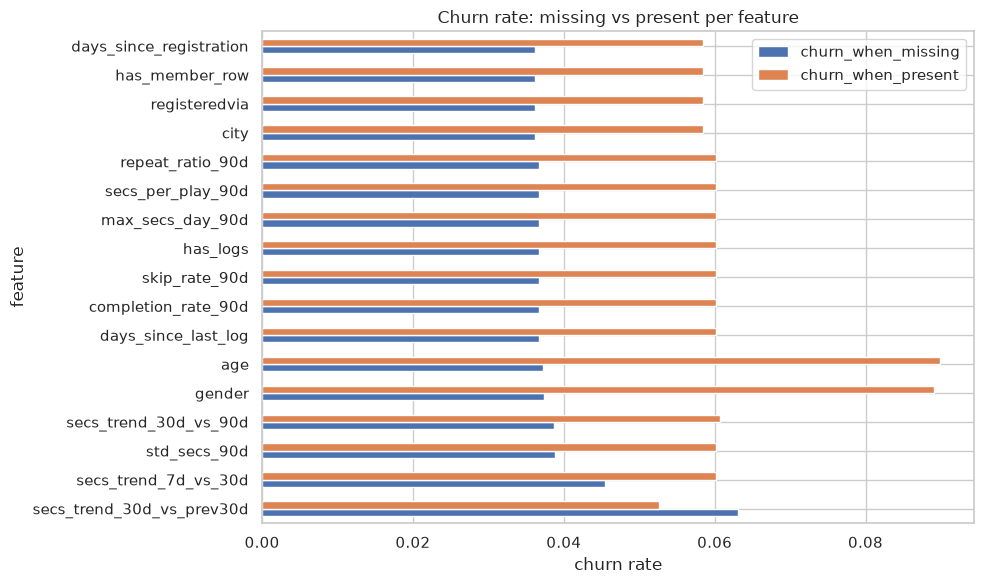

skip_rate_90d   False   True 
has_logs                     
False               0  172014
True           711617       0
std NULL but skip present (single-active-day?): 15392
active_days_90d==1: 15392


In [21]:
fig, ax = plt.subplots(figsize=(10, 6))
miss_churn.plot.barh(x='feature', y=['churn_when_missing','churn_when_present'], ax=ax)
ax.set_xlabel('churn rate')
ax.set_title('Churn rate: missing vs present per feature')
plt.tight_layout(); plt.show()
# also verify structural missing: has_logs=False <=> skip_* NULL? single-day <=> std NULL?
print(pd.crosstab(df['has_logs'], df['skip_rate_90d'].isnull()))
print('std NULL but skip present (single-active-day?):', (df['std_secs_90d'].isnull() & df['skip_rate_90d'].notnull()).sum())
print('active_days_90d==1:', (df['active_days_90d'] == 1).sum())


In [22]:
#leakage check: PK + days_to_expiry (WHERE days_to_expiry BETWEEN 1 AND win, build_features.sql)
print('msno nunique:', df['msno'].nunique(), '| n rows:', len(df), '| dups:', df.duplicated('msno').sum())
exp = df.groupby('days_to_expiry')['label'].agg(rate='mean', n='size')
exp


msno nunique: 883631 | n rows: 883631 | dups: 0


,rate,n
days_to_expiry,,
1,0.056857,25573
2,0.062729,26479
3,0.056666,27759
4,0.057534,29478
5,0.057978,29787
6,0.061369,33942
7,0.064298,28088
8,0.060235,27791
9,0.057374,30345


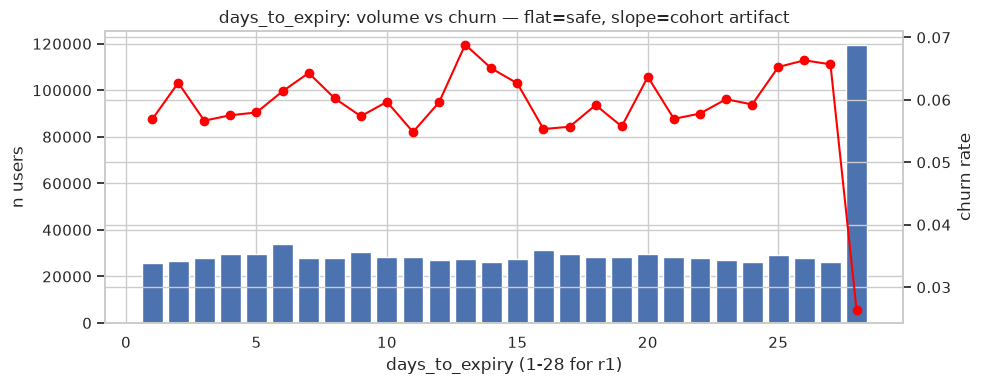

In [23]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(exp.index, exp['n'])
ax1.set_xlabel('days_to_expiry (1-28 for r1)')
ax1.set_ylabel('n users')
ax2 = ax1.twinx()
ax2.plot(exp.index, exp['rate'], marker='o', color='red')
ax2.set_ylabel('churn rate')
plt.title('days_to_expiry: volume vs churn — flat=safe, slope=cohort artifact')
plt.tight_layout(); plt.show()


In [24]:
# sanity bounds (README + build_features.sql logic)
bound_cols = ['age','active_days_7d','active_days_30d','active_days_90d','active_days_prev30d',
 'days_since_registration','days_since_first_trans','days_since_last_log','days_to_expiry']
pd.DataFrame({'min': df[bound_cols].min(), 'max': df[bound_cols].max()})


,min,max
age,10.0,90.0
active_days_7d,0.0,7.0
active_days_30d,0.0,30.0
active_days_90d,0.0,90.0
active_days_prev30d,0.0,30.0
days_since_registration,0.0,4694.0
days_since_first_trans,0.0,761.0
days_since_last_log,0.0,89.0
days_to_expiry,1.0,28.0


In [25]:
print('age out of [10,90]:', ((df['age'] < 10) | (df['age'] > 90)).sum())
print('active_7d>7:', (df['active_days_7d'] > 7).sum(),
 '| 30d>30:', (df['active_days_30d'] > 30).sum(),
 '| 90d>90:', (df['active_days_90d'] > 90).sum(),
 '| prev30>30:', (df['active_days_prev30d'] > 30).sum())
print('days_since_registration<0:', (df['days_since_registration'] < 0).sum())
print('days_since_last_log out of [0,89]:', ((df['days_since_last_log'] < 0) | (df['days_since_last_log'] > 89)).sum())
print('days_to_expiry out of [1,28]:', ((df['days_to_expiry'] < 1) | (df['days_to_expiry'] > 28)).sum())
print('days_since_first_trans max (left-censored ~2015-01-01 => ~762):', df['days_since_first_trans'].max())


age out of [10,90]: 0
active_7d>7: 0 | 30d>30: 0 | 90d>90: 0 | prev30>30: 0
days_since_registration<0: 0
days_since_last_log out of [0,89]: 0
days_to_expiry out of [1,28]: 0
days_since_first_trans max (left-censored ~2015-01-01 => ~762): 761


In [26]:
# categorical cardinality + rare levels (decides one-hot vs target/grouping)
for c in ['city','registeredvia','gender','last_payment_method','last_plan_days','last_list_price','last_amount_paid']:
    vc = df[c].value_counts(dropna=False, normalize=True)
    print('---', c, '| nunique:', df[c].nunique(), '| rare(<1%) levels:', (vc < 0.01).sum())
    print(vc.head(10).round(4).to_string())
    print()
for c in ['has_member_row','has_logs','last_is_autorenew','last_is_cancel']:
    print(c, df[c].value_counts(normalize=True, dropna=False).round(4).to_dict())


--- city | nunique: 21 | rare(<1%) levels: 12
city
1.0     0.4969
NaN     0.1257
13.0    0.0878
5.0     0.0673
4.0     0.0452
22.0    0.0364
15.0    0.0351
6.0     0.0227
14.0    0.0176
12.0    0.0111

--- registeredvia | nunique: 5 | rare(<1%) levels: 1
registeredvia
7.0     0.5240
9.0     0.2051
NaN     0.1257
3.0     0.0940
4.0     0.0482
13.0    0.0030

--- gender | nunique: 2 | rare(<1%) levels: 0
gender
None      0.6464
male      0.1873
female    0.1663

--- last_payment_method | nunique: 33 | rare(<1%) levels: 23
last_payment_method
41    0.6254
40    0.0817
36    0.0702
38    0.0674
37    0.0401
34    0.0318
29    0.0175
30    0.0158
33    0.0147
31    0.0110

--- last_plan_days | nunique: 28 | rare(<1%) levels: 27
last_plan_days
30     0.9741
410    0.0069
120    0.0051
195    0.0045
180    0.0028
7      0.0019
90     0.0015
100    0.0011
395    0.0007
200    0.0004

--- last_list_price | nunique: 36 | rare(<1%) levels: 31
last_list_price
99.0      0.4368
149.0     0.3921
180.

In [27]:
# numeric skew + zero-inflation (decides log1p / winsorize)
num = ['total_paid','avg_paid','secs_7d','secs_30d','secs_90d','secs_prev30d','plays_30d','plays_90d',
 'max_secs_day_90d','n_trans','n_trans_90d','n_cancel','n_no_autorenew','days_since_first_trans','days_since_registration']
desc = df[num].describe(percentiles=[.5, .9, .99]).T
desc['pct_zero'] = (df[num] == 0).mean() * 100
desc['skew'] = df[num].skew()
desc.round(2).sort_values('skew', ascending=False)


,count,mean,std,min,50%,90%,99%,max,pct_zero,skew
avg_paid,883631.0,146.72,144.96,0.00,134.56,159.33,874.85,2000.00,0.19,8.86
secs_7d,883631.0,21929.19,36363.96,0.00,8573.95,59152.55,171858.26,604800.00,31.09,4.12
n_no_autorenew,883631.0,1.18,3.66,0.00,0.00,3.00,20.00,71.00,81.88,3.98
secs_prev30d,883631.0,98710.88,158181.90,0.00,42572.91,259771.81,772243.20,2573518.93,26.15,3.74
secs_90d,883631.0,296147.61,447956.96,0.00,145673.81,755598.80,2174297.23,7671170.43,19.47,3.74
secs_30d,883631.0,101348.99,155359.68,0.00,48730.00,260606.16,757759.98,2569214.60,22.83,3.69
plays_30d,883631.0,518.69,748.79,0.00,266.00,1350.00,3477.00,28433.00,22.83,3.56
plays_90d,883631.0,1516.46,2149.60,0.00,793.00,3916.00,10031.70,78091.00,19.47,3.48
n_cancel,883631.0,0.24,0.54,0.00,0.00,1.00,2.00,20.00,80.32,2.85
max_secs_day_90d,711617.0,21848.96,15234.09,0.03,18934.98,41233.43,78450.82,86400.00,0.00,1.33


In [28]:
# behavior ratios: range check (tiny denominators explode)
trend = ['skip_rate_90d','completion_rate_90d','repeat_ratio_90d','secs_per_play_90d',
 'std_secs_90d','secs_trend_7d_vs_30d','secs_trend_30d_vs_90d','secs_trend_30d_vs_prev30d','active_days_delta']
df[trend].describe(percentiles=[.5, .9, .99, .999]).T.round(3)


,count,mean,std,min,50%,90%,99%,99.9%,max
skip_rate_90d,711617.0,0.251,0.178,0.000,0.214,0.484,0.883,1.000,1.000
completion_rate_90d,711617.0,0.718,0.191,0.000,0.755,0.924,0.987,1.000,1.000
repeat_ratio_90d,711617.0,0.765,0.164,0.003,0.804,0.932,1.000,1.000,1.000
secs_per_play_90d,711617.0,186.538,45.137,0.030,192.975,233.241,259.693,373.867,2725.946
std_secs_90d,696225.0,5167.713,3476.651,0.000,4390.458,9633.308,16922.402,26700.810,60747.800
secs_trend_7d_vs_30d,608924.0,1.173,0.925,0.000,0.942,2.331,4.286,4.286,4.286
secs_trend_30d_vs_90d,681930.0,1.175,0.672,0.000,1.025,2.135,3.000,3.000,3.000
secs_trend_30d_vs_prev30d,632252.0,9.930,1250.549,0.000,0.993,2.701,25.497,554.218,761224.026
active_days_delta,883631.0,0.309,5.278,-30.000,0.000,6.000,19.000,26.000,30.000


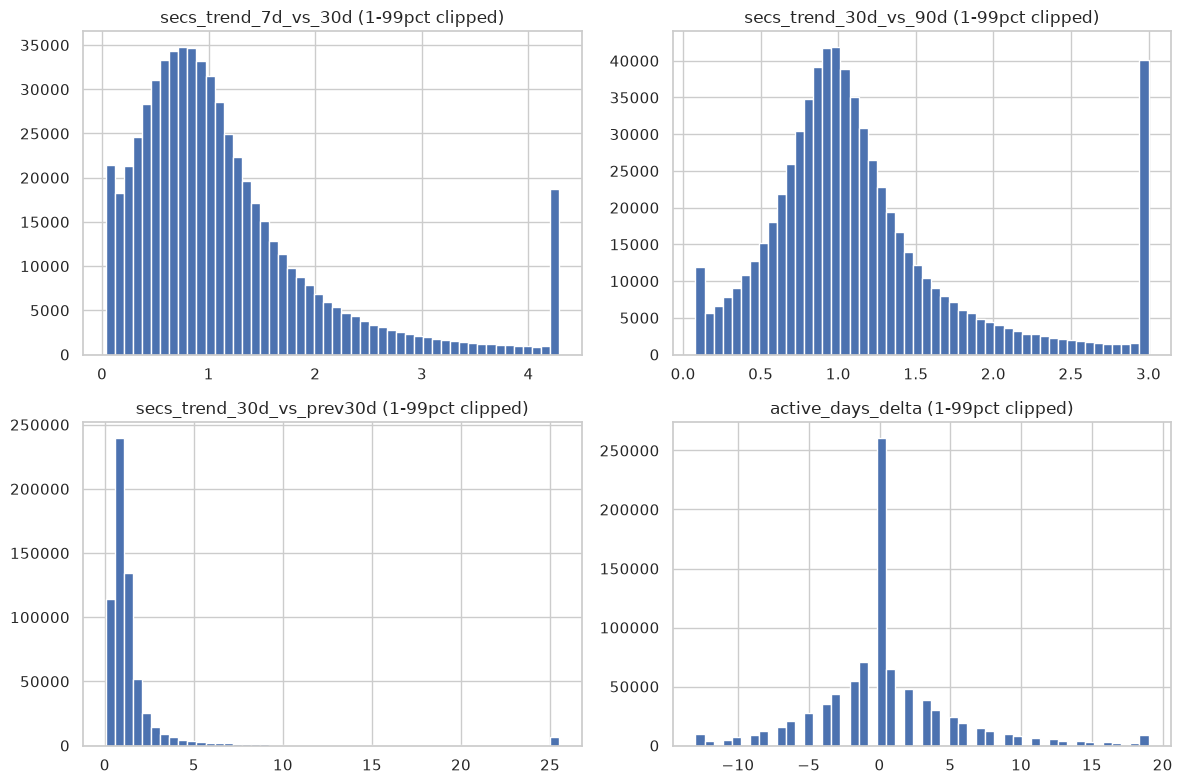

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.flat, ['secs_trend_7d_vs_30d','secs_trend_30d_vs_90d','secs_trend_30d_vs_prev30d','active_days_delta']):
    lo, hi = df[c].quantile([0.01, 0.99])
    ax.hist(df[c].dropna().clip(lo, hi), bins=50)
    ax.set_title(f'{c} (1-99pct clipped)')
plt.tight_layout(); plt.show()


   last_is_autorenew    rate       n
0              False  0.2919  104927
1               True  0.0238  778704



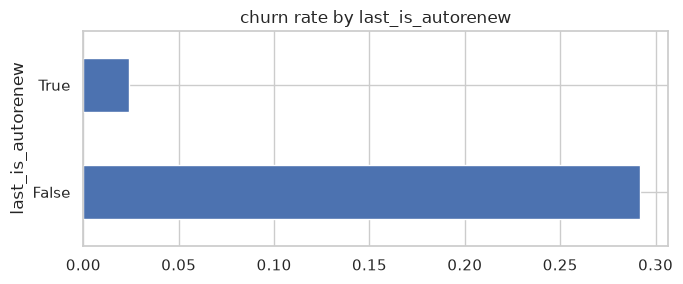

   last_is_cancel    rate       n
1            True  0.6053    3299
0           False  0.0536  880332



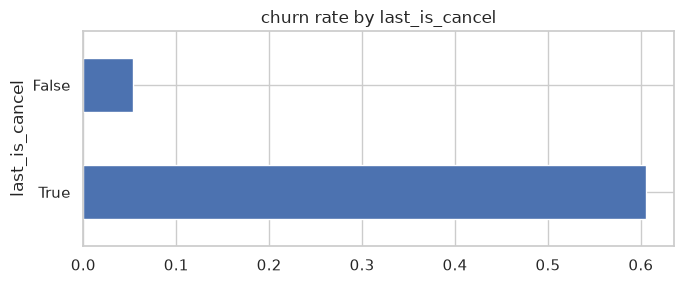

   has_logs    rate       n
1      True  0.0602  711617
0     False  0.0367  172014



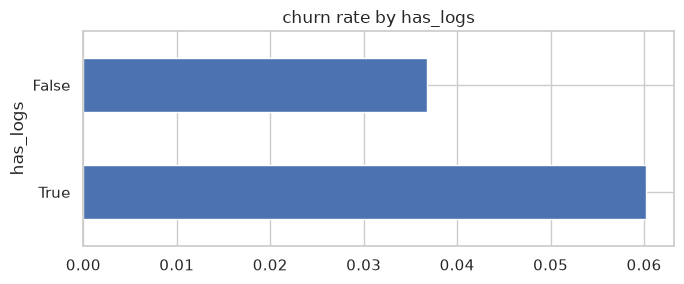

   has_member_row    rate       n
1            True  0.0584  772562
0           False  0.0362  111069



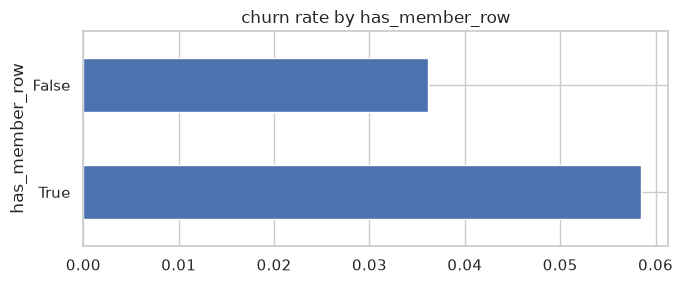

   gender    rate       n
1    male  0.0898  165526
0  female  0.0882  146931
2     NaN  0.0373  571174



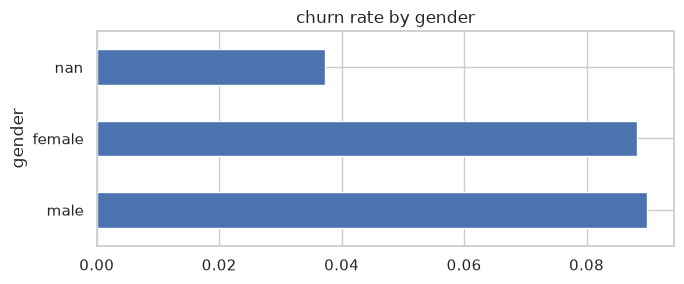

   registeredvia    rate       n
1            4.0  0.1855   42577
0            3.0  0.1378   83057
3            9.0  0.0936  181246
4           13.0  0.0686    2682
5            NaN  0.0362  111069
2            7.0  0.0187  463000



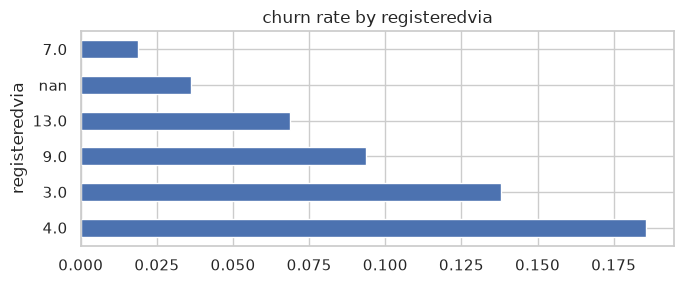

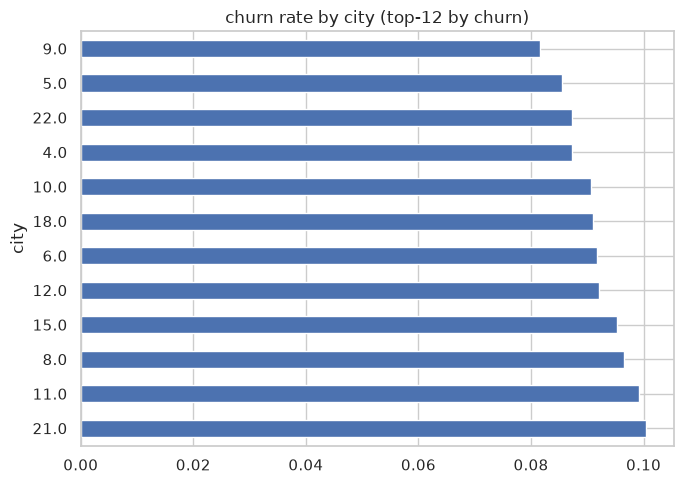

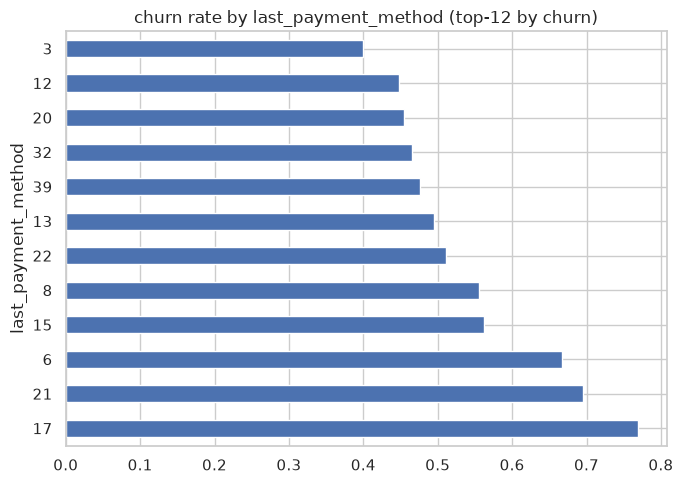

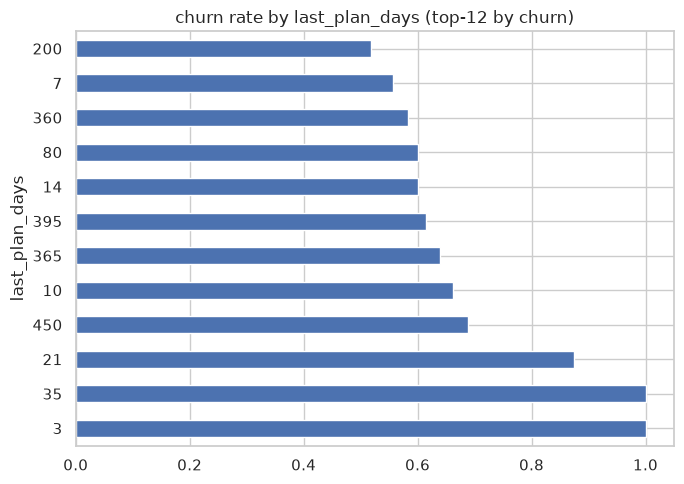

In [30]:
# churn rate by categorical (tests README strong-signal claims)
for c in ['last_is_autorenew','last_is_cancel','has_logs','has_member_row','gender','registeredvia']:
    t = churn_by_cat(c)
    print(t.round(4).to_string()); print()
    t.plot.barh(x=c, y='rate', legend=False, figsize=(7, 3), title=f'churn rate by {c}')
    plt.tight_layout(); plt.show()
for c in ['city','last_payment_method','last_plan_days']:
    t = churn_by_cat(c).head(12)
    t.plot.barh(x=c, y='rate', legend=False, figsize=(7, 5), title=f'churn rate by {c} (top-12 by churn)')
    plt.tight_layout(); plt.show()


--- secs_trend_30d_vs_prev30d
                             rate      n
secs_trend_30d_vs_prev30d               
(-0.00099899, 0.404]       0.0662  63226
(0.404, 0.601]             0.0576  63225
(0.601, 0.744]             0.0519  63225
(0.744, 0.868]             0.0482  63225
(0.868, 0.993]             0.0473  63225
(0.993, 1.142]             0.0471  63225
(1.142, 1.351]             0.0463  63225
(1.351, 1.715]             0.0497  63225
(1.715, 2.701]             0.0521  63225
(2.701, 761224.026]        0.0601  63226



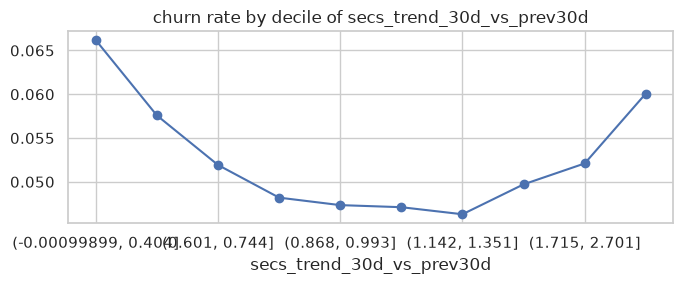

--- secs_trend_7d_vs_30d
                        rate      n
secs_trend_7d_vs_30d               
(-0.00099789, 0.29]   0.0642  60893
(0.29, 0.482]         0.0573  60892
(0.482, 0.642]        0.0558  60892
(0.642, 0.791]        0.0537  60893
(0.791, 0.942]        0.0531  60892
(0.942, 1.11]         0.0533  60892
(1.11, 1.325]         0.0537  60893
(1.325, 1.649]        0.0559  60892
(1.649, 2.331]        0.0615  60892
(2.331, 4.286]        0.0934  60893



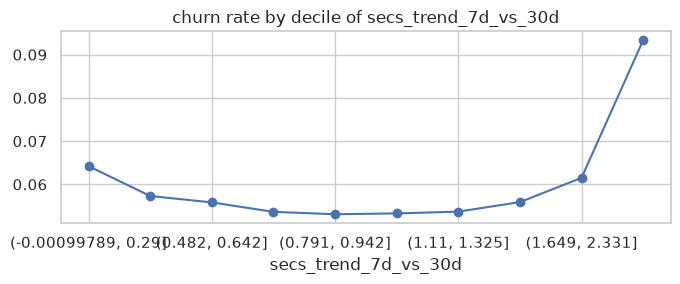

--- active_days_delta
                     rate       n
active_days_delta                
(-30.001, -5.0]    0.0662  110824
(-5.0, -3.0]       0.0500   78328
(-3.0, -1.0]       0.0471  125492
(-1.0, 0.0]        0.0399  260819
(0.0, 1.0]         0.0527   65086
(1.0, 3.0]         0.0574   86283
(3.0, 6.0]         0.0660   73949
(6.0, 30.0]        0.1005   82850



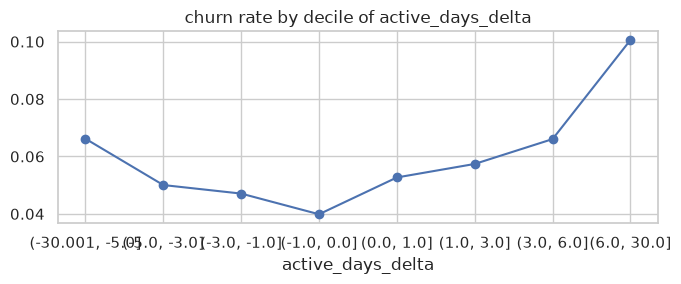

--- days_since_last_log
                       rate       n
days_since_last_log                
(-0.001, 1.0]        0.0596  452285
(1.0, 2.0]           0.0622   52578
(2.0, 5.0]           0.0611   88384
(5.0, 10.0]          0.0642   47210
(10.0, 89.0]         0.0587   71160



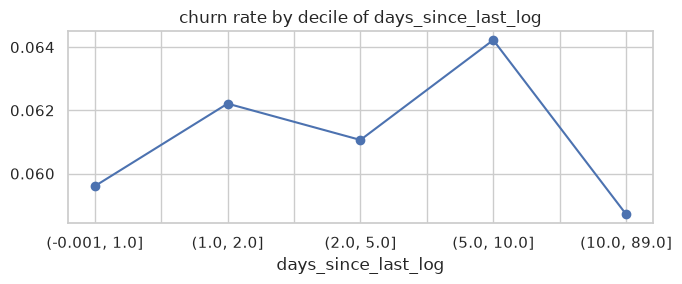

--- secs_30d
                             rate       n
secs_30d                                 
(-0.001, 7741.725]         0.0438  265090
(7741.725, 26024.435]      0.0714   88363
(26024.435, 48730.004]     0.0681   88363
(48730.004, 76450.03]      0.0628   88363
(76450.03, 112164.703]     0.0604   88363
(112164.703, 163418.344]   0.0556   88363
(163418.344, 260606.163]   0.0549   88363
(260606.163, 2569214.603]  0.0516   88363



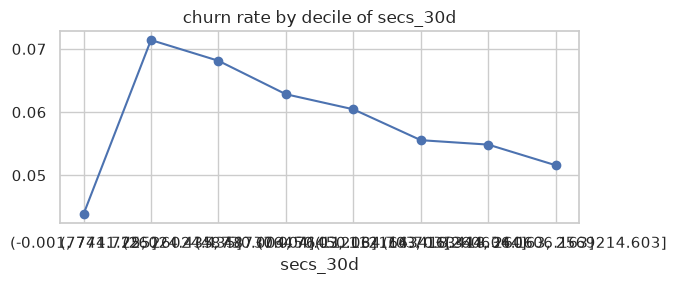

--- active_days_30d
                   rate       n
active_days_30d                
(-0.001, 3.0]    0.0464  269956
(3.0, 8.0]       0.0749   95552
(8.0, 13.0]      0.0698   94193
(13.0, 17.0]     0.0641   78787
(17.0, 21.0]     0.0589   86097
(21.0, 25.0]     0.0530   98219
(25.0, 28.0]     0.0482   85409
(28.0, 30.0]     0.0457   75418



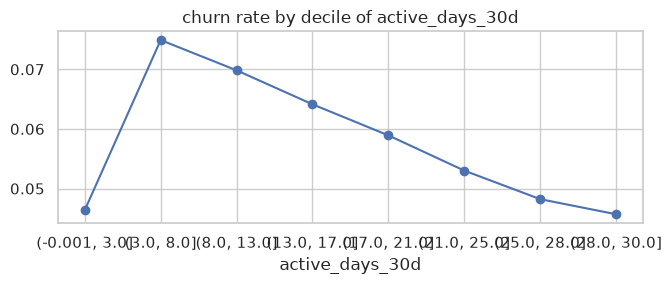

--- n_no_autorenew
                  rate       n
n_no_autorenew                
(-0.001, 3.0]   0.0423  797577
(3.0, 71.0]     0.1789   86054



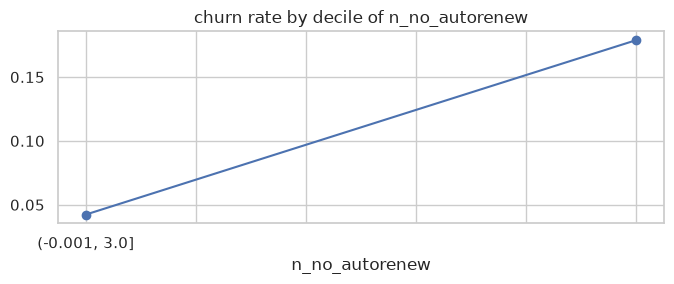

--- avg_paid
                      rate       n
avg_paid                          
(-0.001, 99.0]      0.0239  336237
(99.0, 110.538]     0.0516   17241
(110.538, 134.556]  0.0388   88428
(134.556, 149.0]    0.0508  329254
(149.0, 159.333]    0.1017   24355
(159.333, 2000.0]   0.1999   88116



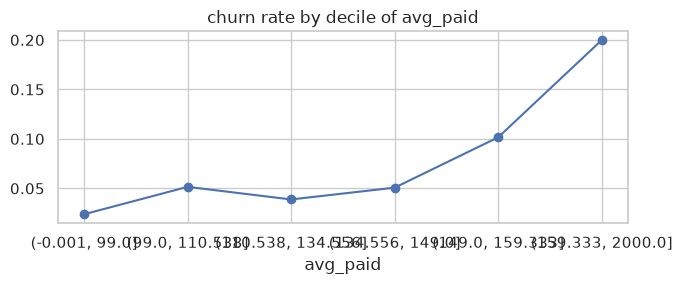

--- days_since_first_trans
                          rate      n
days_since_first_trans               
(-0.001, 104.0]         0.1066  89022
(104.0, 206.0]          0.0554  88241
(206.0, 328.0]          0.0453  88056
(328.0, 400.0]          0.0891  88605
(400.0, 479.0]          0.0458  88477
(479.0, 573.0]          0.0351  88369
(573.0, 679.0]          0.0519  87971
(679.0, 740.0]          0.0588  89328
(740.0, 751.0]          0.0342  88703
(751.0, 761.0]          0.0332  86859



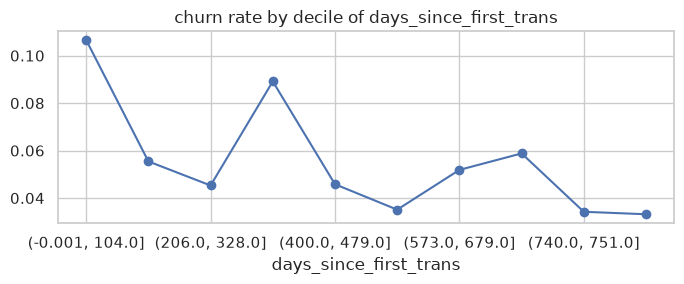

--- age
                 rate      n
age                         
(9.999, 20.0]  0.1643  35687
(20.0, 22.0]   0.1274  27539
(22.0, 24.0]   0.0986  31026
(24.0, 26.0]   0.0825  32919
(26.0, 28.0]   0.0750  33123
(28.0, 30.0]   0.0737  28335
(30.0, 33.0]   0.0738  32908
(33.0, 36.0]   0.0697  25995
(36.0, 42.0]   0.0677  31317
(42.0, 90.0]   0.0565  30349



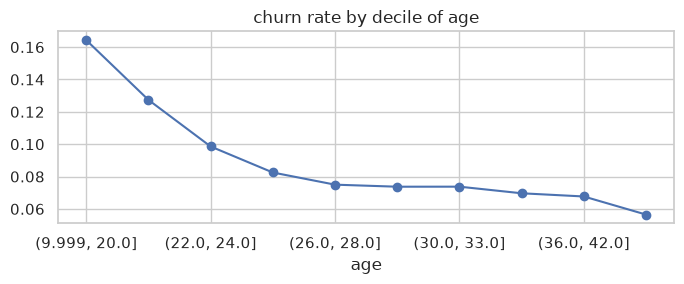

--- discount_gap
                   rate       n
discount_gap                   
(-0.001, 180.0]  0.0556  883631



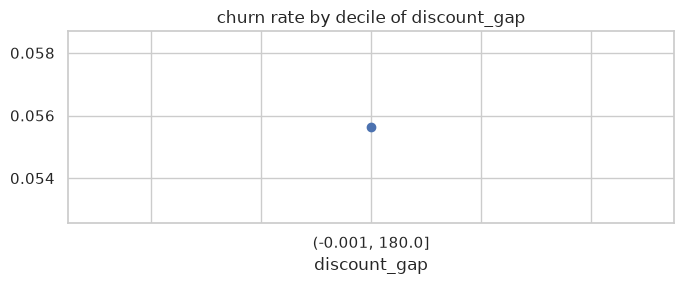

In [31]:
# numeric vs churn by decile (keep/drop + transform signal)
df['discount_gap'] = df['last_list_price'] - df['last_amount_paid']
candidates = ['secs_trend_30d_vs_prev30d','secs_trend_7d_vs_30d','active_days_delta','days_since_last_log',
 'secs_30d','active_days_30d','n_no_autorenew','avg_paid','days_since_first_trans','age','discount_gap']
for c in candidates:
    t = churn_by_decile(c)
    print('---', c); print(t.round(4).to_string()); print()
    t['rate'].plot(marker='o', figsize=(7, 3), title=f'churn rate by decile of {c}')
    plt.tight_layout(); plt.show()
df.drop(columns=['discount_gap'], inplace=True)


In [32]:
# zero-activity slice: inactive but subscribed?
df['is_inactive_30d'] = df['secs_30d'] == 0
print(pd.crosstab(df['is_inactive_30d'], df['last_is_autorenew'], values=df['label'], aggfunc='mean').round(4))
print(pd.crosstab(df['is_inactive_30d'], df['last_is_autorenew'], values=df['label'], aggfunc='size'))
print('churn|inactive:', df.loc[df['is_inactive_30d'], 'label'].mean().round(4),
 '| churn|active:', df.loc[~df['is_inactive_30d'], 'label'].mean().round(4))
df.drop(columns=['is_inactive_30d'], inplace=True)


last_is_autorenew   False   True 
is_inactive_30d                  
False              0.2854  0.0203
True               0.8974  0.0339
last_is_autorenew   False   True 
is_inactive_30d                  
False              103816  578114
True                 1111  200590
churn|inactive: 0.0387 | churn|active: 0.0606


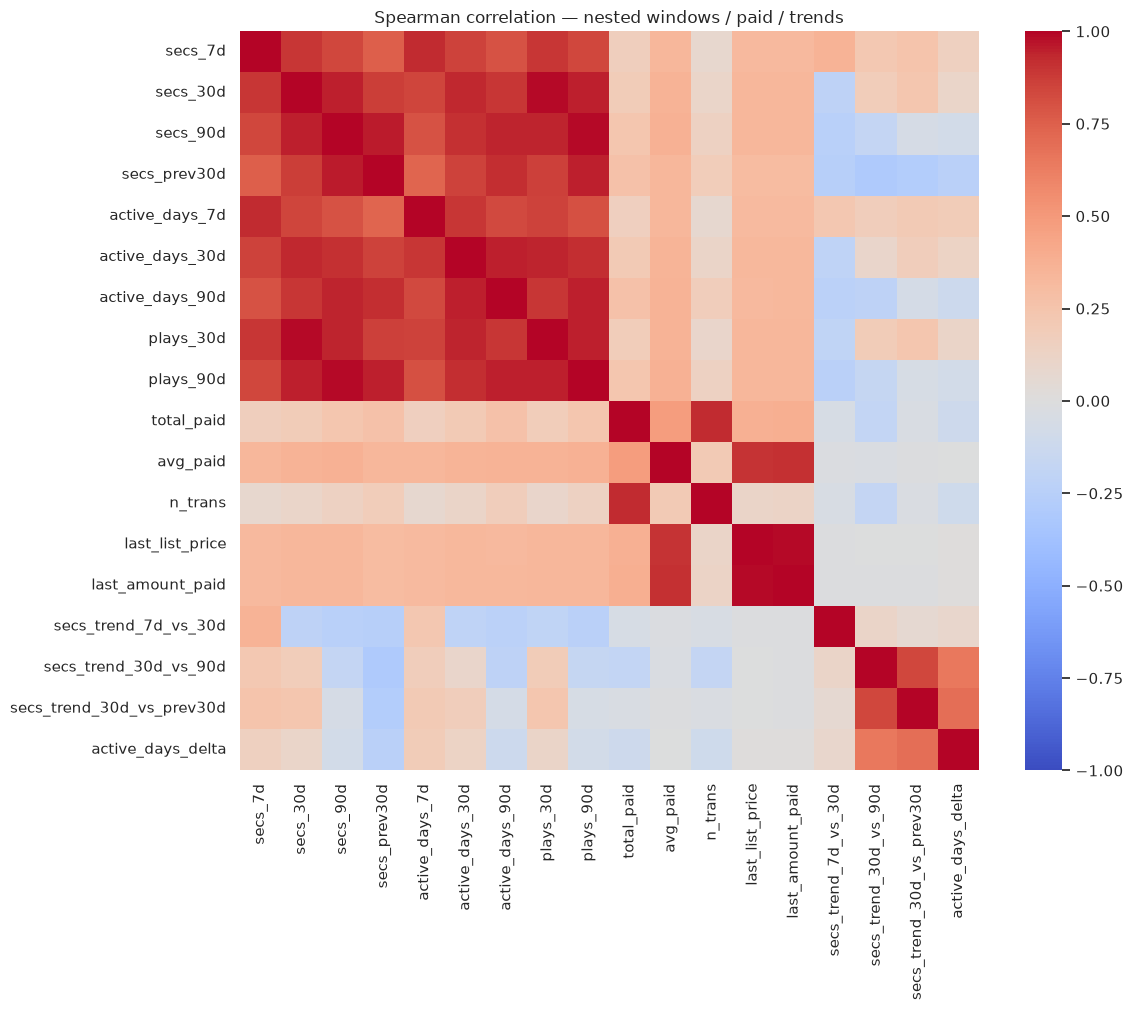

plays_90d          secs_90d                     0.991747
secs_90d           plays_90d                    0.991747
last_amount_paid   last_list_price              0.991379
last_list_price    last_amount_paid             0.991379
secs_30d           plays_30d                    0.991199
                                                  ...   
active_days_delta  last_amount_paid                  NaN
                   secs_trend_7d_vs_30d              NaN
                   secs_trend_30d_vs_90d             NaN
                   secs_trend_30d_vs_prev30d         NaN
                   active_days_delta                 NaN
Length: 324, dtype: float64

In [43]:
# redundancy: Spearman corr (nested 7d/30d/90d overlap by construction)
corr_cols = ['secs_7d','secs_30d','secs_90d','secs_prev30d','active_days_7d','active_days_30d',
 'active_days_90d','plays_30d','plays_90d','total_paid','avg_paid','n_trans',
 'last_list_price','last_amount_paid','secs_trend_7d_vs_30d','secs_trend_30d_vs_90d',
 'secs_trend_30d_vs_prev30d','active_days_delta']
corr = df[corr_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, vmin=-1, vmax=1, cmap='coolwarm', square=True, ax=ax)
ax.set_title('Spearman correlation — nested windows / paid / trends')
plt.tight_layout(); plt.show()
corr.where((corr.abs() > 0.8) & (corr < 1.0)).stack().sort_values(ascending=False)


## Decisions log (r1: 883,631 users, churn 5.56%)

### 1. `days_to_expiry` - uneven cohort, handle with care
- Days 1–27 look alike: churn is between 5.5% and 6.9%, with about 26k–34k users per day.  
- Day 28 is different: churn is only 2.6%, but it holds 119,356 users (13.5% of the data).  
**Decision: keep the column, but stratify validation on `days_to_expiry == 28`, and run a drop-vs-keep ablation before trusting it.**  

### 2. Member-profile missingness - missing means something (MNAR)
- `city`, `registeredvia` and `days_since_registration` are missing together in 12.6% of rows. That is exactly the `has_member_row = False` group. Churn is 3.6% when missing vs 5.8% when present.
- `gender` is missing in 64.6% of rows and `age` in 65.0%; they are missing together in 63.8%. Churn is 3.7% when missing vs about 8.9% when known. Among known genders there is no gap: male 9.0%, female 8.8%.  
**Decision: keep `has_member_row` as a feature. Encode missing `city` / `registeredvia` as an explicit `MISSING` category. Fill `age` with the median and add an `age_is_missing` flag. Keep `gender` as three levels: male / female / missing.**

### 3. Listening-log missingness - structural, not random
- 19.5% of users have no log rows at all (`has_logs = False`). For them, `skip_rate`, `completion_rate`, `repeat_ratio`, `secs_per_play`, `max_secs_day` and `days_since_last_log` are all missing too. Their churn is 3.7% vs 6.0% for users with logs.
- `std_secs_90d` is missing in 21.2%. The extra 1.7 points are 15,392 users with exactly one active day, for whom a standard deviation cannot be computed.
- Trend columns are missing more often (23–31%) because their denominators are zero when the user was silent in the baseline window. Users missing `30d_vs_prev30d` churn at 6.3% vs 5.3% when present, the reverse of the other trends.  
**Decision: keep `has_logs`. Add an `is_single_day` flag. For trend columns, add a missing indicator and fill with the median (tree models) or use a model that handles NULL natively. Do not plain mean-impute.**

### 4. `city` (21 values) - one big safe city vs the rest
- City `1.0` holds 439,119 users (about 50%) and churns at 3.7%.
- Every other city churns between 7.3% and 10.0% (highest: `21.0` at 10.0%, `11.0` at 9.9%).
- 12 of the 21 cities each cover less than 1% of users.
**Decision: group cities below 1% into `OTHER`. Encode with an `is_city_1` flag plus smoothed target encoding. Do not one-hot 21 columns.**

### 5. `last_payment_method` (33 values) - very predictive, very fragile
- Method `41` holds 552,579 users (62.5%) and churns at only 1.8%. Methods `34` (0.9%) and `31` (0.9%) are similarly safe.
- The middle band: `36` and `30` at about 11%, `29` at 18%, `38` at 28%.
- The top band (`32` at 46%, `39` at 48%, `22` at 51%) looks alarming, but the most extreme rates (50–77%) come from methods with fewer than 100 users — those numbers are noise.
- 23 of the 33 methods each cover less than 1% of users.  
**Decision: group methods with fewer than ~1,000 users into `OTHER_RISK`. Use target encoding with cross-validation and smoothing, or collapse into low / mid / high risk tiers. Never one-hot all 33, and never trust the raw rate of a tiny group.**

### 6. `last_plan_days` (28 values) - monthly plan vs everything else
- The 30-day plan holds 860,718 users (97.4%) and churns at 4.5%.
- Every other plan length churns between roughly 35% and 100% (e.g. `410` at 49.5% with 6,068 users, `7` at 55.6% with 1,692 users). Plans with 1–8 users at 60–100% churn are noise.
**Decision: collapse to a single `is_plan_30` flag (optionally short / monthly / long). Drop the raw 28-level column.**

### 7. Skewed numbers — transform before modeling
- `avg_paid` is heavily right-skewed (skew 8.9): median 135, 99th percentile 875, max 2,000.
- Listening volumes (`secs_*`, `plays_*`) have skew 3.5–4.1 with 19–31% exact zeros.
- `n_no_autorenew` is zero for 81.9% of users; `n_cancel` is zero for 80.3%.
- `total_paid`, `n_trans` and tenure are well-behaved and need no transform.
**Decision: apply `log1p` plus 1st–99th percentile winsorization to `avg_paid`, `secs_*`, `plays_*` and `std_secs`. Convert `n_no_autorenew` and `n_cancel` into a `> 0` flag plus a capped count.**

### 8. Trend features — keep two, fix one explosion, drop one
- `secs_trend_30d_vs_prev30d` is U-shaped: churn is 6.6% when activity collapsed, about 4.6% in the stable middle, and 6.0% when it spiked. Both sharp decline and sharp growth predict churn.
- `active_days_delta` behaves the same way, and growth predicts even more strongly: a gain of 6+ days churns at 10.1%, a drop of 5+ days at 6.6%, stable users at 4.0%.
- `secs_trend_7d_vs_30d` above 2.33 churns at 9.3% (a sudden recent surge).
- `days_since_last_log` is flat (5.9–6.4% everywhere) — recency alone adds little once we know the user has logs.
- `secs_trend_30d_vs_prev30d` explodes numerically (mean 9.9, 99th percentile 25.5, max 761,224) whenever the previous-30-day denominator is near zero.
**Decision: keep `30d_vs_prev30d` and `active_days_delta`, binned or splined rather than linear. Clip `30d_vs_prev30d` at the 0.1st–99.9th percentiles and log it. Drop `30d_vs_90d` — it correlates 0.84 with the cleaner `30d_vs_prev30d` and separates churn less well.**

### 9. Strongest single signals — keep all, add one interaction
- Auto-renew off: 29.2% churn (104,927 users) vs auto-renew on: 2.4% (778,704). This is the dominant signal, a 12× gap.
- Last transaction was a cancellation: 60.5% churn — but only 3,299 users.
- More than 3 non-auto-renew transactions: 17.9% vs 4.2% otherwise.
- High average payment: above 159 churns at 20.0% vs 2.4% at 99 or below. Paying more predicts churning more.
- Young users: age 20 or below churns at 16.4%, falling steadily to 5.7% at age 42+. New customers (tenure under 104 days) churn at 10.7% vs 3.3% for the oldest cohort.
- Registration channel `4.0` churns at 18.6% vs channel `7.0` at 1.9%.
- Paradox: silent users churn LESS overall (3.9% vs 6.1% for active users) — unless auto-renew is off. Silent plus no auto-renew churns at 89.7% (1,111 users) vs 28.5% for active plus no auto-renew.
**Decision: keep every signal above. Add an explicit `autorenew × inactive_30d` interaction — activity alone misleads without it.**

### 10. `discount_gap` (list price minus paid) — drop it
- The gap is effectively zero for nearly all rows: deciling it produced a single bin.
**Decision: drop `discount_gap` as a continuous feature. Use the existing `n_discounted > 0` flag instead.**

### 11. Redundant pairs (|Spearman r| > 0.8) — keep one of each
- Listening activity is one cluster: `plays_90`/`secs_90` at 0.99, `secs_30`/`plays_30` at 0.99, all window pairs at 0.80–0.99.
- Money is one cluster: `list_price`/`amount_paid` at 0.99, `total_paid`/`n_trans` at 0.93, `avg_paid` with each at about 0.91.
- Note: the long `NaN` block in the correlation output is not missing data — it is just the `> 0.8` filter hiding everything else.
**Decision: keep `secs_30d`, `active_days_30d` and `active_days_delta`; drop `plays_30d`, `plays_90d`, `secs_7d`, `secs_90d`, `secs_prev30d`. Keep `avg_paid` and `n_trans`; drop `total_paid` and one of `list_price` / `amount_paid`.**

### 12. Class imbalance (5.56% churn) — evaluation setup
**Decision: stratified splits (also stratify `day28`), optimize PR-AUC / recall@k rather than accuracy, and use `class_weight` or sampling.**
